In [42]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress, norm, percentileofscore, fisher_exact, chi2_contingency
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import pyreadr
import statistics as stats
import math
from tabulate import tabulate
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib.patches as patches
import pyBigWig
import re
import pysam
import upsetplot

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)

1
1


In [3]:
n_cycles, n_comps, n_DHSs = mixture_all_cycles.shape

In [4]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [5]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [6]:
tsv_file = open("/home/meuleman/work/projects/ENCODE3/WM20180608_733_sample_metadata/ENCODE 733-sample list WM20180608 - ENCODE3 metadata.tsv")
biosample_df2 = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
cycle0_dhs_int_arr = cycle0_dhs_arr.astype(int)
n_biosamples, n_DHSs = cycle0_dhs_arr.shape

In [8]:
num_biosamples = np.sum(cycle0_dhs_int_arr, axis=0)
num_DHSs = np.sum(cycle0_dhs_int_arr, axis=1)

In [9]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/max_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220322.npy'
DHS_max_signal_array = np.load(file)

In [10]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [11]:
flipped_recon = np.append(added_recon_all_cycles[0], removed_recon_all_cycles[0])

In [25]:
#biosample and DHS inds
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

flipped_DHS_inds = np.append(added_DHS_inds, removed_DHS_inds)
flipped_biosample_inds = np.append(added_biosample_inds, removed_biosample_inds)

In [26]:
#new and old components
added_DHS_original_comps = mixture_all_cycles_top_comp[0, added_DHS_inds]
added_DHS_new_comps = mixture_all_cycles_top_comp[1, added_DHS_inds]
removed_DHS_original_comps = mixture_all_cycles_top_comp[0, removed_DHS_inds]
removed_DHS_new_comps = mixture_all_cycles_top_comp[1, removed_DHS_inds]

added_biosample_original_comps = basis_all_cycles_top_comp[0, added_biosample_inds]
added_biosample_new_comps = basis_all_cycles_top_comp[1, added_biosample_inds]
removed_biosample_original_comps = basis_all_cycles_top_comp[0, removed_biosample_inds]
removed_biosample_new_comps = basis_all_cycles_top_comp[1, removed_biosample_inds]

flipped_DHS_original_comps = np.append(added_DHS_original_comps, removed_DHS_original_comps)
flipped_DHS_new_comps = np.append(added_DHS_new_comps, removed_DHS_new_comps)
flipped_biosample_original_comps = np.append(added_biosample_original_comps, removed_biosample_original_comps)
flipped_biosample_new_comps = np.append(added_biosample_new_comps, removed_biosample_new_comps)

In [27]:
#delta vals
removed_delta_all_cycles = removed_recon_all_cycles[0] - 1
added_delta_all_cycles = added_recon_all_cycles[0]

flipped_delta = np.append(added_delta_all_cycles, removed_delta_all_cycles)

In [28]:
#number of biosamples/DHSs
added_num_biosamples = num_biosamples[added_DHS_inds]
removed_num_biosamples = num_biosamples[removed_DHS_inds]

added_num_DHSs = num_DHSs[added_biosample_inds]
removed_num_DHSs = num_DHSs[removed_biosample_inds]

flipped_num_biosamples = np.append(added_num_biosamples, removed_num_biosamples)
flipped_num_DHSs = np.append(added_num_DHSs, removed_num_DHSs)

In [29]:
#max signal
added_max_signal = DHS_max_signal_array[added_biosample_inds, added_DHS_inds]
removed_max_signal = DHS_max_signal_array[removed_biosample_inds, removed_DHS_inds]

flipped_max_signal = np.append(added_max_signal, removed_max_signal)

In [30]:
#finding minimum max signal for positive calls
flipped_min_max_signal = []
for dhs in np.append(added_DHS_inds, removed_DHS_inds):
    flipped_min_max_signal.append(np.min(DHS_max_signal_array[cycle0_dhs_arr[:, dhs], dhs]))
flipped_min_max_signal = np.array(flipped_min_max_signal)

In [31]:
flipped_added_v_removed = np.append(np.array(['Added']*len(added_biosample_inds)), np.array(['Removed']*len(removed_biosample_inds)))

In [32]:
#distance for removed calls

removed_DHS_identifiers = np.array(DHS_metadata.loc[removed_DHS_inds]['identifier'])

removed_biosample_ln = np.array(biosample_df.loc[removed_biosample_inds]['Altius Library ID'])
removed_biosample_ln_stripped = np.array([])
for ln in removed_biosample_ln:
    if ln[-1].isalpha():
        removed_biosample_ln_stripped = np.append(removed_biosample_ln_stripped, ln[:-1])
    else:
        removed_biosample_ln_stripped = np.append(removed_biosample_ln_stripped, ln)
        
identifier2chunk = {}
chunk2identifier = {}
f = open("/home/meuleman/projects/ENCODE3/WM20180608_construct_masterlist_733samples/masterlist_DHSs_733samples_WM20180608_all_chunkIDs2indexIDs.txt", "r")
for line in f:
    line = line.strip().split('\t')
    identifier2chunk[line[0]] = line[1]
    chunk2identifier[line[1]] = line[0]
f.close()

#finding the chunks of each removed DHS
removed_DHS_chunks = np.array([])
for identifier in removed_DHS_identifiers:
    removed_DHS_chunks = np.append(removed_DHS_chunks, identifier2chunk[identifier])

pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_per_biosample_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'rb')
removed_DHS_calls=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_median_smooth_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'rb')
removed_DHS_original_peaks=pickle.load(pickle_in)

DHS_identifiers = np.array(DHS_metadata['identifier'])

identifier2ind = {}
for i in range(len(DHS_identifiers)):
    identifier2ind[DHS_identifiers[i]] = i
    
all_ln_nums = np.array(biosample_df['Altius Library ID'])
all_ln_stripped = np.array([])
for ln in all_ln_nums:
    if ln[-1].isalpha():
        all_ln_stripped = np.append(all_ln_stripped, ln[:-1])
    else:
        all_ln_stripped = np.append(all_ln_stripped, ln)
        
def percentile_range(all_scores, score):
    num_scores = len(all_scores)
    sorted_scores = np.sort(all_scores)
    sorted_score_inds = np.where(sorted_scores==score)[0]
    high_rank = sorted_score_inds[-1]+1
    low_rank = sorted_score_inds[0]
    high_percentile = high_rank/num_scores*100
    low_percentile = low_rank/num_scores*100
    weight = 1/len(sorted_score_inds)
    return low_percentile, high_percentile, weight

#distances from each removed call peak to consesus peak
removed_max_distance_from_consensus = []
removed_scores = []
removed_score_percentiles = []
removed_distances = []
removed_distance_percentiles = []
removed_outside_cores = []

for chunk_info, removed_ln in zip(removed_DHS_calls, 
                                  removed_biosample_ln_stripped):
    
    #chunk
    chunk = chunk_info[0, -1]
    #peak location
    peak_location = np.median(chunk_info[:, 6].astype(int))
    #start and end of core region
    core_95 = np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5]).astype(int) #removed ceil function to better match metadata
    core_start = core_95[0]
    core_end = core_95[1]
    DHS_ind = identifier2ind[chunk2identifier[chunk_info[0, 7]]]
    DHS_start = int(DHS_metadata.loc[DHS_ind]['start'])
    DHS_end = int(DHS_metadata.loc[DHS_ind]['end'])
    if core_start < DHS_start:
        core_start = DHS_start
    if core_end > DHS_end:
        core_end = DHS_end
    
    #all calls distance from consensus
    all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
    
    #removed biosample local ind
    removed_inds = np.where(chunk_info==removed_ln)[0]
    
    #scores for all calls
    scores = chunk_info[:, 4].astype(float)
    
    #max distance from all calls to consensus peak
    max_distance_from_consensus = np.max(np.abs(chunk_info[:, 6].astype(int) - peak_location))
    removed_max_distance_from_consensus.append(max_distance_from_consensus)
    
    
    score_call = []
    score_percentile_call = []
    distance_call = []
    distance_percentile_call = []
    outside_core_call = []
    
    for removed_ind in removed_inds:
        removed_peak = chunk_info[removed_ind, 6].astype(int)
        if ((removed_peak < core_start) | (removed_peak > core_end)):
            outside_core_call.append('yes')
        else:
            outside_core_call.append('no')
        
        
        #distance of removed call from peak
        removed_peak_distance_from_consensus = np.abs(chunk_info[removed_ind, 6].astype(int) - peak_location)
        distance_call.append(removed_peak_distance_from_consensus)
        #percentile of distance
        distance_percentile_range = percentile_range(all_distances, removed_peak_distance_from_consensus)
        
        #score percentile
        score = chunk_info[removed_ind, 4].astype(float)
        score_call.append(score)
        #score percentile
        score_percentile_range = percentile_range(scores, score)
        
        #averaging percentiles
        average_distance_per = int(np.mean(distance_percentile_range[:2]))
        distance_percentile_call.append(average_distance_per)
        average_score_per = int(np.mean(score_percentile_range[:2]))
        score_percentile_call.append(average_score_per)
        
    removed_scores.append(score_call)
    removed_score_percentiles.append(score_percentile_call)
    removed_distances.append(distance_call)
    removed_distance_percentiles.append(distance_percentile_call)
    removed_outside_cores.append(outside_core_call)

**DataFrame Construction**

In [33]:
# flipped_metadata_dict = {'biosample_ind' : flipped_biosample_inds, 
#                          'DHS_ind' : flipped_DHS_inds, 
#                          'recon_val' : flipped_recon, 
#                          'delta_val' : flipped_delta, 
#                          'added_v_removed' : flipped_added_v_removed, 
#                          'num_biosamples_for_DHS' : flipped_num_biosamples, 
#                          'num_DHSs_for_biosample' : flipped_num_DHSs, 
#                          'biosample_original_comp' : flipped_biosample_original_comps, 
#                          'biosample_new_comp' : flipped_biosample_new_comps, 
#                          'DHS_original_comp' : flipped_DHS_original_comps, 
#                          'DHS_new_comps' : flipped_DHS_new_comps,
#                          'max_signal' : flipped_max_signal,
#                          'removed_score' : np.array([np.nan]*len(flipped_biosample_inds)),
#                          'removed_score_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
#                          'removed_distance' : np.array([np.nan]*len(flipped_biosample_inds)),
#                          'removed_distance_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
#                          'removed_outside_core' : np.array([np.nan]*len(flipped_biosample_inds)),
#                          'removed_DHS_max_call_distance' : np.array([np.nan]*len(flipped_biosample_inds))}

# flipped_metadata_df = pd.DataFrame(flipped_metadata_dict)

# flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_score'] = np.array(removed_scores, dtype=object)
# flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_score_percentile'] = np.array(removed_score_percentiles, dtype=object)
# flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_distance'] = np.array(removed_distances, dtype=object)
# flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_distance_percentile'] = np.array(removed_distance_percentiles, dtype=object)
# flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_outside_core'] = np.array(removed_outside_cores, dtype=object)
# flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_DHS_max_call_distance'] = np.array(removed_max_distance_from_consensus)

In [34]:
flipped_metadata_dict = {'biosample_ind' : flipped_biosample_inds, 
                         'DHS_ind' : flipped_DHS_inds, 
                         'recon_val' : flipped_recon, 
                         'delta_val' : flipped_delta, 
                         'added_v_removed' : flipped_added_v_removed, 
                         'num_biosamples_for_DHS' : flipped_num_biosamples, 
                         'num_DHSs_for_biosample' : flipped_num_DHSs, 
                         'biosample_original_comp' : flipped_biosample_original_comps, 
                         'biosample_new_comp' : flipped_biosample_new_comps, 
                         'DHS_original_comp' : flipped_DHS_original_comps, 
                         'DHS_new_comp' : flipped_DHS_new_comps,
                         'max_signal' : flipped_max_signal,
                         'min_max_signal_for_DHS' : flipped_min_max_signal,
                         'removed_score' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_score' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_score_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_score_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_distance' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_distance' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_distance_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_distance_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_outside_core' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'summary_removed_outside_core' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_DHS_max_call_distance' : np.array([np.nan]*len(flipped_biosample_inds))}

flipped_metadata_df = pd.DataFrame(flipped_metadata_dict)

flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_score'] = np.array(removed_scores, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_score_percentile'] = np.array(removed_score_percentiles, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_distance'] = np.array(removed_distances, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_distance_percentile'] = np.array(removed_distance_percentiles, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_outside_core'] = np.array(removed_outside_cores, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_DHS_max_call_distance'] = np.array(removed_max_distance_from_consensus)

average_removed_scores = []
for i in removed_scores:
    if len(i)>1:
        average_removed_scores.append(np.mean(i))
    else:
        average_removed_scores.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_score'] = np.array(average_removed_scores)

average_removed_score_percentiles = []
for i in removed_score_percentiles:
    if len(i)>1:
        average_removed_score_percentiles.append(np.mean(i))
    else:
        average_removed_score_percentiles.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_score_percentile'] = np.array(average_removed_score_percentiles)

average_removed_distances = []
for i in removed_distances:
    if len(i)>1:
        average_removed_distances.append(np.mean(i))
    else:
        average_removed_distances.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_distance'] = np.array(average_removed_distances)

average_removed_distance_percentiles = []
for i in removed_distance_percentiles:
    if len(i)>1:
        average_removed_distance_percentiles.append(np.mean(i))
    else:
        average_removed_distance_percentiles.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_distance_percentile'] = np.array(average_removed_distance_percentiles)

summary_removed_outside_cores = []
for i in removed_outside_cores:
    if ((len(i)>1) & ('yes' in i) & ('no' in i)):
        summary_removed_outside_cores.append('yes and no')
    elif ((len(i)>1) & ('yes' in i) & ('no' not in i)):
        summary_removed_outside_cores.append('yes')
    elif ((len(i)>1) & ('yes' not in i) & ('no' in i)):
        summary_removed_outside_cores.append('no')
    else:
        summary_removed_outside_cores.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'summary_removed_outside_core'] = np.array(summary_removed_outside_cores)

In [35]:
removed_metadata_df = flipped_metadata_df[flipped_metadata_df['added_v_removed']=='Removed']

In [37]:
removed_metadata_df[removed_metadata_df['biosample_original_comp']!=removed_metadata_df['DHS_original_comp']]

,biosample_ind,DHS_ind,recon_val,delta_val,added_v_removed,num_biosamples_for_DHS,num_DHSs_for_biosample,biosample_original_comp,biosample_new_comp,DHS_original_comp,...,average_removed_score,removed_score_percentile,average_removed_score_percentile,removed_distance,average_removed_distance,removed_distance_percentile,average_removed_distance_percentile,removed_outside_core,summary_removed_outside_core,removed_DHS_max_call_distance
46842,0,61585,0.0,-1.0,Removed,72,82918,4,4,2,...,0.215682,[7],7.0,[20.0],20.0,[73],73.0,[no],no,80.0
46843,420,3438004,0.0,-1.0,Removed,24,61565,11,11,2,...,1.670140,[43],43.0,[40.0],40.0,[85],85.0,[no],no,40.0
46844,420,3398495,0.0,-1.0,Removed,73,61565,11,11,8,...,0.385416,[55],55.0,[0.0],0.0,[12],12.0,[no],no,220.0
46845,420,3353412,0.0,-1.0,Removed,115,61565,11,11,12,...,1.445310,[44],44.0,[100.0],100.0,[99],99.0,[yes],yes,100.0
46846,420,3125385,0.0,-1.0,Removed,149,61565,11,11,2,...,0.738714,[45],45.0,[80.0],80.0,[96],96.0,[yes],yes,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69287,198,1232572,0.0,-1.0,Removed,135,63263,1,1,2,...,0.573081,[67],67.0,[0.0],0.0,[34],34.0,[no],no,40.0
69288,198,1215546,0.0,-1.0,Removed,136,63263,1,1,2,...,0.573081,[68],68.0,[0.0],0.0,[20],20.0,[no],no,60.0
69289,198,1212771,0.0,-1.0,Removed,146,63263,1,1,5,...,0.668595,[64],64.0,[0.0],0.0,[23],23.0,[no],no,76.0
69290,198,1497849,0.0,-1.0,Removed,82,63263,1,1,3,...,1.384950,[61],61.0,[20.0],20.0,[36],36.0,[no],no,100.0


In [53]:
distance_thresh=0.

0.5

In [55]:
removed_metadata_df[((removed_metadata_df['average_removed_distance_percentile'] < distance_thresh))]

,biosample_ind,DHS_ind,recon_val,delta_val,added_v_removed,num_biosamples_for_DHS,num_DHSs_for_biosample,biosample_original_comp,biosample_new_comp,DHS_original_comp,...,average_removed_score,removed_score_percentile,average_removed_score_percentile,removed_distance,average_removed_distance,removed_distance_percentile,average_removed_distance_percentile,removed_outside_core,summary_removed_outside_core,removed_DHS_max_call_distance
46842,0,61585,0.0,-1.0,Removed,72,82918,4,4,2,...,0.215682,[7],7.0,[20.0],20.0,[73],73.0,[no],no,80.0
46844,420,3398495,0.0,-1.0,Removed,73,61565,11,11,8,...,0.385416,[55],55.0,[0.0],0.0,[12],12.0,[no],no,220.0
46849,420,2895995,0.0,-1.0,Removed,68,61565,11,11,5,...,1.252600,[55],55.0,[20.0],20.0,[66],66.0,[no],no,100.0
46850,420,2882235,0.0,-1.0,Removed,75,61565,11,11,5,...,0.642360,[87],87.0,[0.0],0.0,[15],15.0,[no],no,100.0
46853,420,2577945,0.0,-1.0,Removed,56,61565,11,11,3,...,0.738714,[31],31.0,[20.0],20.0,[51],51.0,[no],no,80.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69287,198,1232572,0.0,-1.0,Removed,135,63263,1,1,2,...,0.573081,[67],67.0,[0.0],0.0,[34],34.0,[no],no,40.0
69288,198,1215546,0.0,-1.0,Removed,136,63263,1,1,2,...,0.573081,[68],68.0,[0.0],0.0,[20],20.0,[no],no,60.0
69289,198,1212771,0.0,-1.0,Removed,146,63263,1,1,5,...,0.668595,[64],64.0,[0.0],0.0,[23],23.0,[no],no,76.0
69290,198,1497849,0.0,-1.0,Removed,82,63263,1,1,3,...,1.384950,[61],61.0,[20.0],20.0,[36],36.0,[no],no,100.0


In [89]:
score_thresh = 10
distance_thresh = 90

score_less_distance_less_DHSs = np.array(removed_metadata_df[((removed_metadata_df['average_removed_distance_percentile'] < distance_thresh) & 
                                                              (removed_metadata_df['average_removed_score_percentile'] < score_thresh))]['DHS_ind'])
score_greater_distance_less_DHSs = np.array(removed_metadata_df[((removed_metadata_df['average_removed_distance_percentile'] < distance_thresh) & 
                                                                 (removed_metadata_df['average_removed_score_percentile'] >= score_thresh))]['DHS_ind'])
score_less_distance_greater_DHSs = np.array(removed_metadata_df[((removed_metadata_df['average_removed_distance_percentile'] >= distance_thresh) & 
                                                                 (removed_metadata_df['average_removed_score_percentile'] < score_thresh))]['DHS_ind'])
score_greater_distance_greater_DHSs = np.array(removed_metadata_df[((removed_metadata_df['average_removed_distance_percentile'] >= distance_thresh) & 
                                                                    (removed_metadata_df['average_removed_score_percentile'] >= score_thresh))]['DHS_ind'])

In [90]:
removed_call_upset = upsetplot.from_memberships(
    [['Summit Outlier', 'Signal Outlier', 'Strong NMF Disagreement', 'Non-Canonical Component'],
     ['Summit Outlier', 'Strong NMF Disagreement', 'Non-Canonical Component'],
     ['Signal Outlier', 'Strong NMF Disagreement', 'Non-Canonical Component'],
     ['Strong NMF Disagreement', 'Non-Canonical Component'],
     ],
     data=[len(score_less_distance_greater_DHSs), 
           len(score_greater_distance_greater_DHSs), 
           len(score_less_distance_less_DHSs), 
           len(score_greater_distance_less_DHSs),
          ]
)

Text(0, 0.5, 'Number of Calls')

<Figure size 720x720 with 0 Axes>

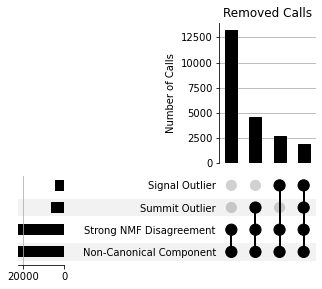

In [91]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

upsetplot.plot(removed_call_upset)


plt.title('Removed Calls')
plt.ylabel('Number of Calls')

In [92]:
score_less_distance_less_DHSs_set = set(score_less_distance_less_DHSs)
score_greater_distance_less_DHSs_set = set(score_greater_distance_less_DHSs)
score_less_distance_greater_DHSs_set = set(score_less_distance_greater_DHSs)
score_greater_distance_greater_DHSs_set = set(score_greater_distance_greater_DHSs)

In [93]:
score_less_distance_less_DHSs_only = (score_less_distance_less_DHSs_set - 
                                      score_greater_distance_less_DHSs_set - 
                                      score_less_distance_greater_DHSs_set - 
                                      score_greater_distance_greater_DHSs_set)
score_greater_distance_less_DHSs_only = (score_greater_distance_less_DHSs_set - 
                                         score_less_distance_less_DHSs_set - 
                                         score_less_distance_greater_DHSs_set - 
                                         score_greater_distance_greater_DHSs_set)
score_less_distance_greater_DHSs_only = (score_less_distance_greater_DHSs_set - 
                                         score_less_distance_less_DHSs_set - 
                                         score_greater_distance_less_DHSs_set - 
                                         score_greater_distance_greater_DHSs_set)
score_greater_distance_greater_DHSs_only = (score_greater_distance_greater_DHSs_set - 
                                            score_less_distance_less_DHSs_set - 
                                            score_greater_distance_less_DHSs_set - 
                                            score_less_distance_greater_DHSs_set)

In [97]:
# see quality_of_NMF_recon_threshold_flip_01thresh_peak_removal_analysis for removal plots
print(np.array(list(score_less_distance_less_DHSs_only))[:10])
print(np.array(list(score_greater_distance_greater_DHSs_only))[:15])
print(np.array(list(score_less_distance_greater_DHSs_only))[:10])

[3293189 3391499 3448844 2768910 1138706 1572891 3399711 1998879  950318
   57397]
[1859586 3465218 2736131 1810437 2195464 3375113 2072585 2310155  352267
  360465 3440659  983059 1015828 2433046 1687574]
[1826816 1835013  557062  958477 1867811 2719782 2170922 2801706 3014700
  188462]
